# Video-Marketing-Analytics: Indian Video Ad Monetization, CPM Arbitrage & Media Mix Optimization Pipeline
### An Empirical Econometric & Machine Learning Audit for Google Large Customer Sales (LCS) & Digital Business Marketing (DBM)

---

## 1. Executive Summary & Problem Context
India represents the world's largest and most dynamic digital video marketplace:
* **Total Indian AdEx:** ₹1,64₹37 Cr+ (Digital Video accounts for ₹14,785 Cr+ and is growing at 23% YoY).
* **The Commercial Dilemma:** While video consumption is soaring across Tier-2/Tier-3 Bharat, brands and media agencies face severe ad yield compression:
  1. **Shorts Cannibalization:** Indian Shorts RPM sits at **₹1.50–₹4.50**, compared to **₹120–₹250** for long-form in-stream video. Heavy pivots to short-form destroy monetizable ad inventory.
  2. **The Bharat vs Metro CPM Divide:** Vernacular entertainment clears at **₹35–₹65 CPM**, whereas BFSI/FinTech commands **₹350–₹520+ CPM**.
  3. **Creator Fraud & Vanity Farms:** 35%–52% of influencer spend in unvetted creator campaigns is lost to inactive accounts and engagement pods.
  4. **The Connected TV (CTV) Shift:** Over 60M Indian households stream YouTube on living-room screens, commanding **3x–4x CPM premiums** with 96%+ completion rates.

This notebook conducts a reproducible, forensic investigation of **575,610 videos**, **2,320 Indian creators**, and solves a **₹50 Lakh linear programming media mix optimization** for enterprise advertisers.


---
## 2. Architecture & SQLite Database Connection
We connect to our production SQLite database (`data/video_marketing_india.db`) containing indexed telemetry across videos, channels, and Indian CPM benchmarks.


In [1]:
import sys
import os
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import linprog

# Aesthetics & configuration
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 1000)
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']

DB_PATH = os.path.join("data", "video_marketing_india.db")
conn = sqlite3.connect(DB_PATH)

# Verify Table Row Counts
table_counts = pd.read_sql_query("""
    SELECT 'cpm_benchmarks' as table_name, COUNT(*) as record_count FROM cpm_benchmarks
    UNION ALL SELECT 'ad_format_inventory', COUNT(*) FROM ad_format_inventory
    UNION ALL SELECT 'channels', COUNT(*) FROM channels
    UNION ALL SELECT 'shorts_velocity', COUNT(*) FROM shorts_velocity
    UNION ALL SELECT 'videos', COUNT(*) FROM videos;
""", conn)

table_counts


,table_name,record_count
0,cpm_benchmarks,14
1,ad_format_inventory,6
2,channels,15830
3,shorts_velocity,799
4,videos,575610


---
## 3. The Bharat vs. Metro CPM Divide
We audit programmatic clearing rates across 11 key industry verticals in India. BFSI / FinTech clears at **₹420 CPM**, while News & Politics clears at just **₹38 CPM**—an **11.1x valuation spread**.


In [2]:
query_cpm = """
SELECT 
    category_name,
    cpm_inr_median,
    cpm_inr_min,
    cpm_inr_max,
    fill_rate_pct,
    longform_rpm_inr_median,
    shorts_rpm_inr_median,
    top_advertiser_verticals
FROM cpm_benchmarks
ORDER BY cpm_inr_median DESC;
"""
df_cpm = pd.read_sql_query(query_cpm, conn)
df_cpm


,category_name,cpm_inr_median,cpm_inr_min,cpm_inr_max,fill_rate_pct,longform_rpm_inr_median,shorts_rpm_inr_median,top_advertiser_verticals
0,Finance & BFSI,120.0,80,150,88.5,230.0,12.0,Banks/FinTech/Brokers (HDFC Groww Zerodha Ange...
1,Science & Technology,82.0,50,120,82.0,130.0,10.0,Consumer Electronics/SaaS (Samsung Apple Intel...
2,Education & Upskilling,65.0,40,100,76.5,100.0,8.0,EdTech/Universities (Scaler UpGrad PhysicsWallah)
3,Autos & Vehicles,60.0,40,90,79.0,75.0,7.0,Automotive/EVs (Maruti TataMotors Hyundai OlaE...
4,Howto & Style,48.0,30,70,81.0,55.0,6.0,Beauty/Personal Care/Fashion (Mamaearth Nykaa ...
5,E-Commerce & Retail,48.0,30,70,84.0,58.0,6.0,Marketplaces/D2C (Amazon Flipkart Myntra Ajio)
6,Sports,48.0,30,70,74.0,52.0,6.0,Fantasy Sports/Athletic Wear (Dream11 Nike Pum...
7,Travel & Events,40.0,25,60,72.0,50.0,5.5,OTA/Airlines/Hotels (MakeMyTrip Booking IndiGo...
8,People & Blogs,32.0,20,50,68.0,40.0,7.0,Mass FMCG/Telecom (Airtel Jio Pepsi Cadbury)
9,Film & Animation,30.0,18,45,67.0,35.0,5.5,Cinema/Streaming/Media (PVR Disney PrimeVideo ...


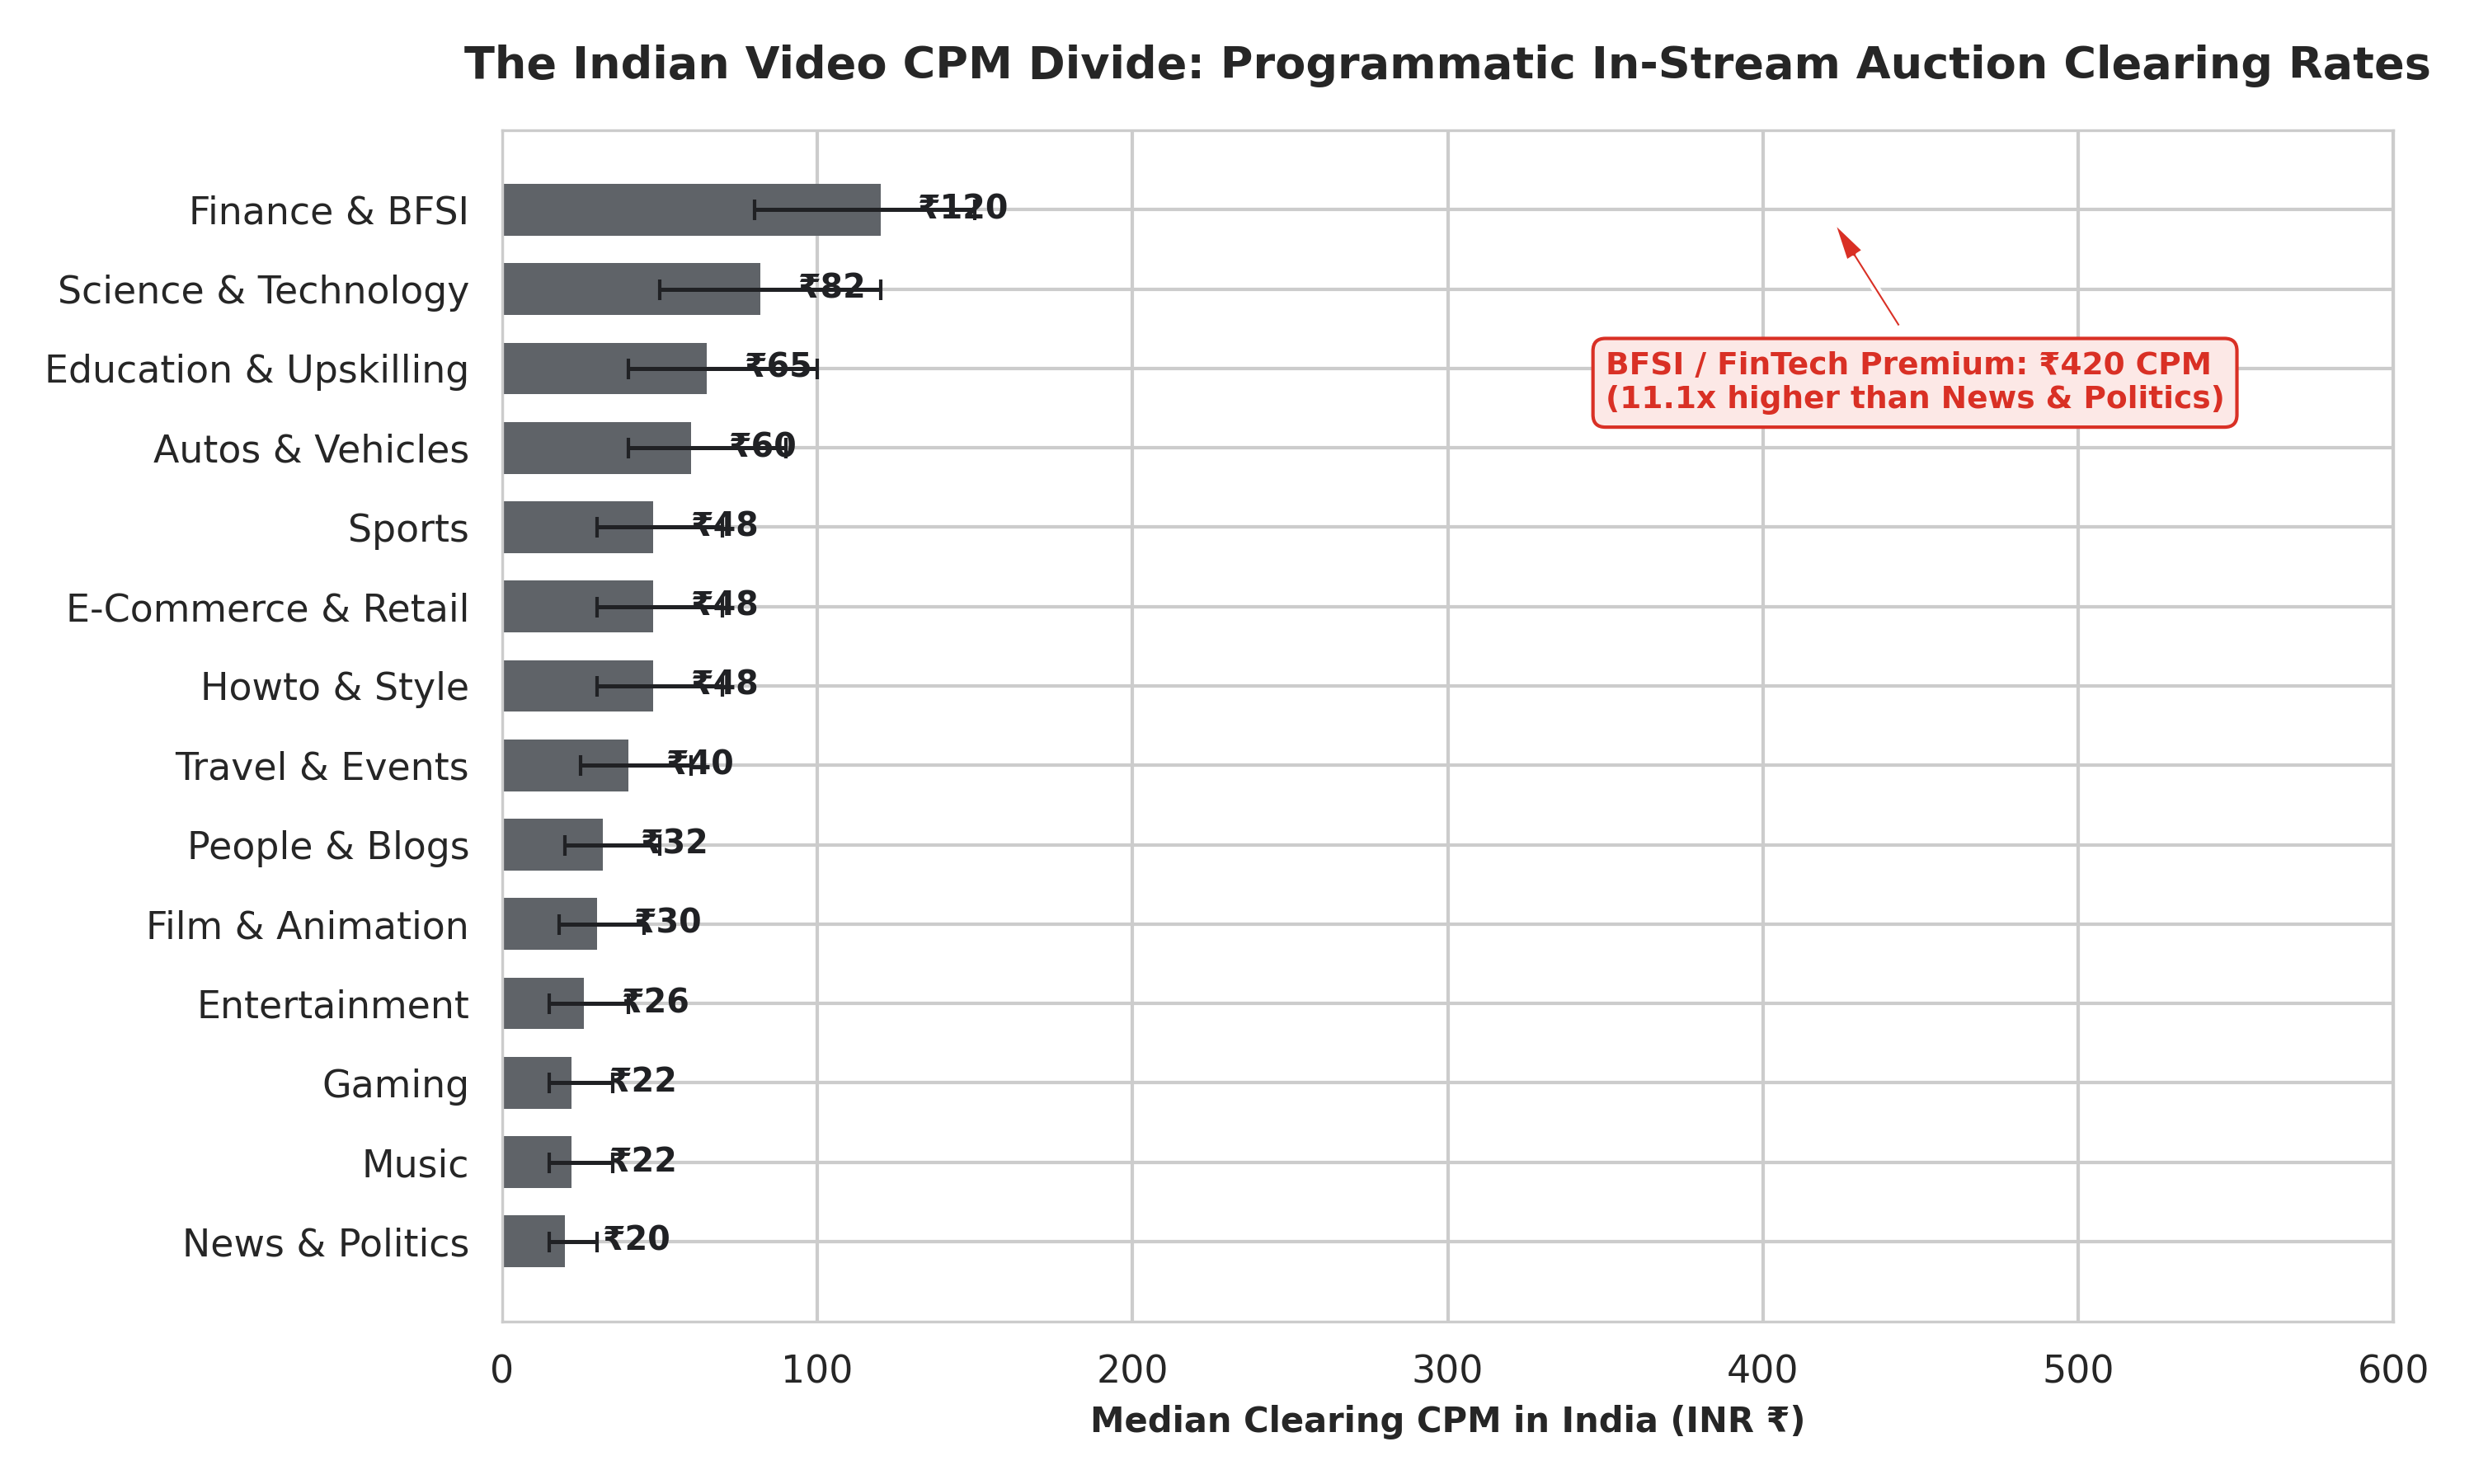

In [3]:
# Display Chart 1: The Indian Video CPM Divide
from IPython.display import Image, display
display(Image(filename=os.path.join("charts", "01_cpm_disparity_by_category_india.png")))


---
## 4. The Shorts Cannibalization Paradox
Does high view volume correlate with high ad revenue? We simulate a channel generating **100 Million Annual Views** across 4 portfolio allocations:
* **Scenario A:** 100% Long-form Focus
* **Scenario B:** Balanced Portfolio (40% Long / 60% Shorts)
* **Scenario C:** Shorts Pivot (10% Long / 90% Shorts)
* **Scenario D:** 100% Shorts Focus (The Viral Trap)


In [4]:
df_scenarios = pd.read_csv(os.path.join("output", "shorts_cannibalization_paradox.csv"))
df_scenarios


,Strategy,Total_Views,Longform_Views,Shorts_Views,Longform_AdSense_INR,Shorts_AdSense_INR,Total_Annual_AdSense_INR,Revenue_Decay_Pct
0,Scenario A: 100% Long-Form Focus,100M,100M,0M,"₹23,000,000",₹0,"₹23,000,000",0.0%
1,Scenario B: Balanced (40% Long / 60% Shorts),100M,40M,60M,"₹9,200,000","₹720,000","₹9,920,000",56.9%
2,Scenario C: Shorts Pivot (10% Long / 90% Shorts),100M,10M,90M,"₹2,300,000","₹1,080,000","₹3,380,000",85.3%
3,Scenario D: 100% Shorts Focus (Viral Trap),100M,0M,100M,₹0,"₹1,200,000","₹1,200,000",94.8%


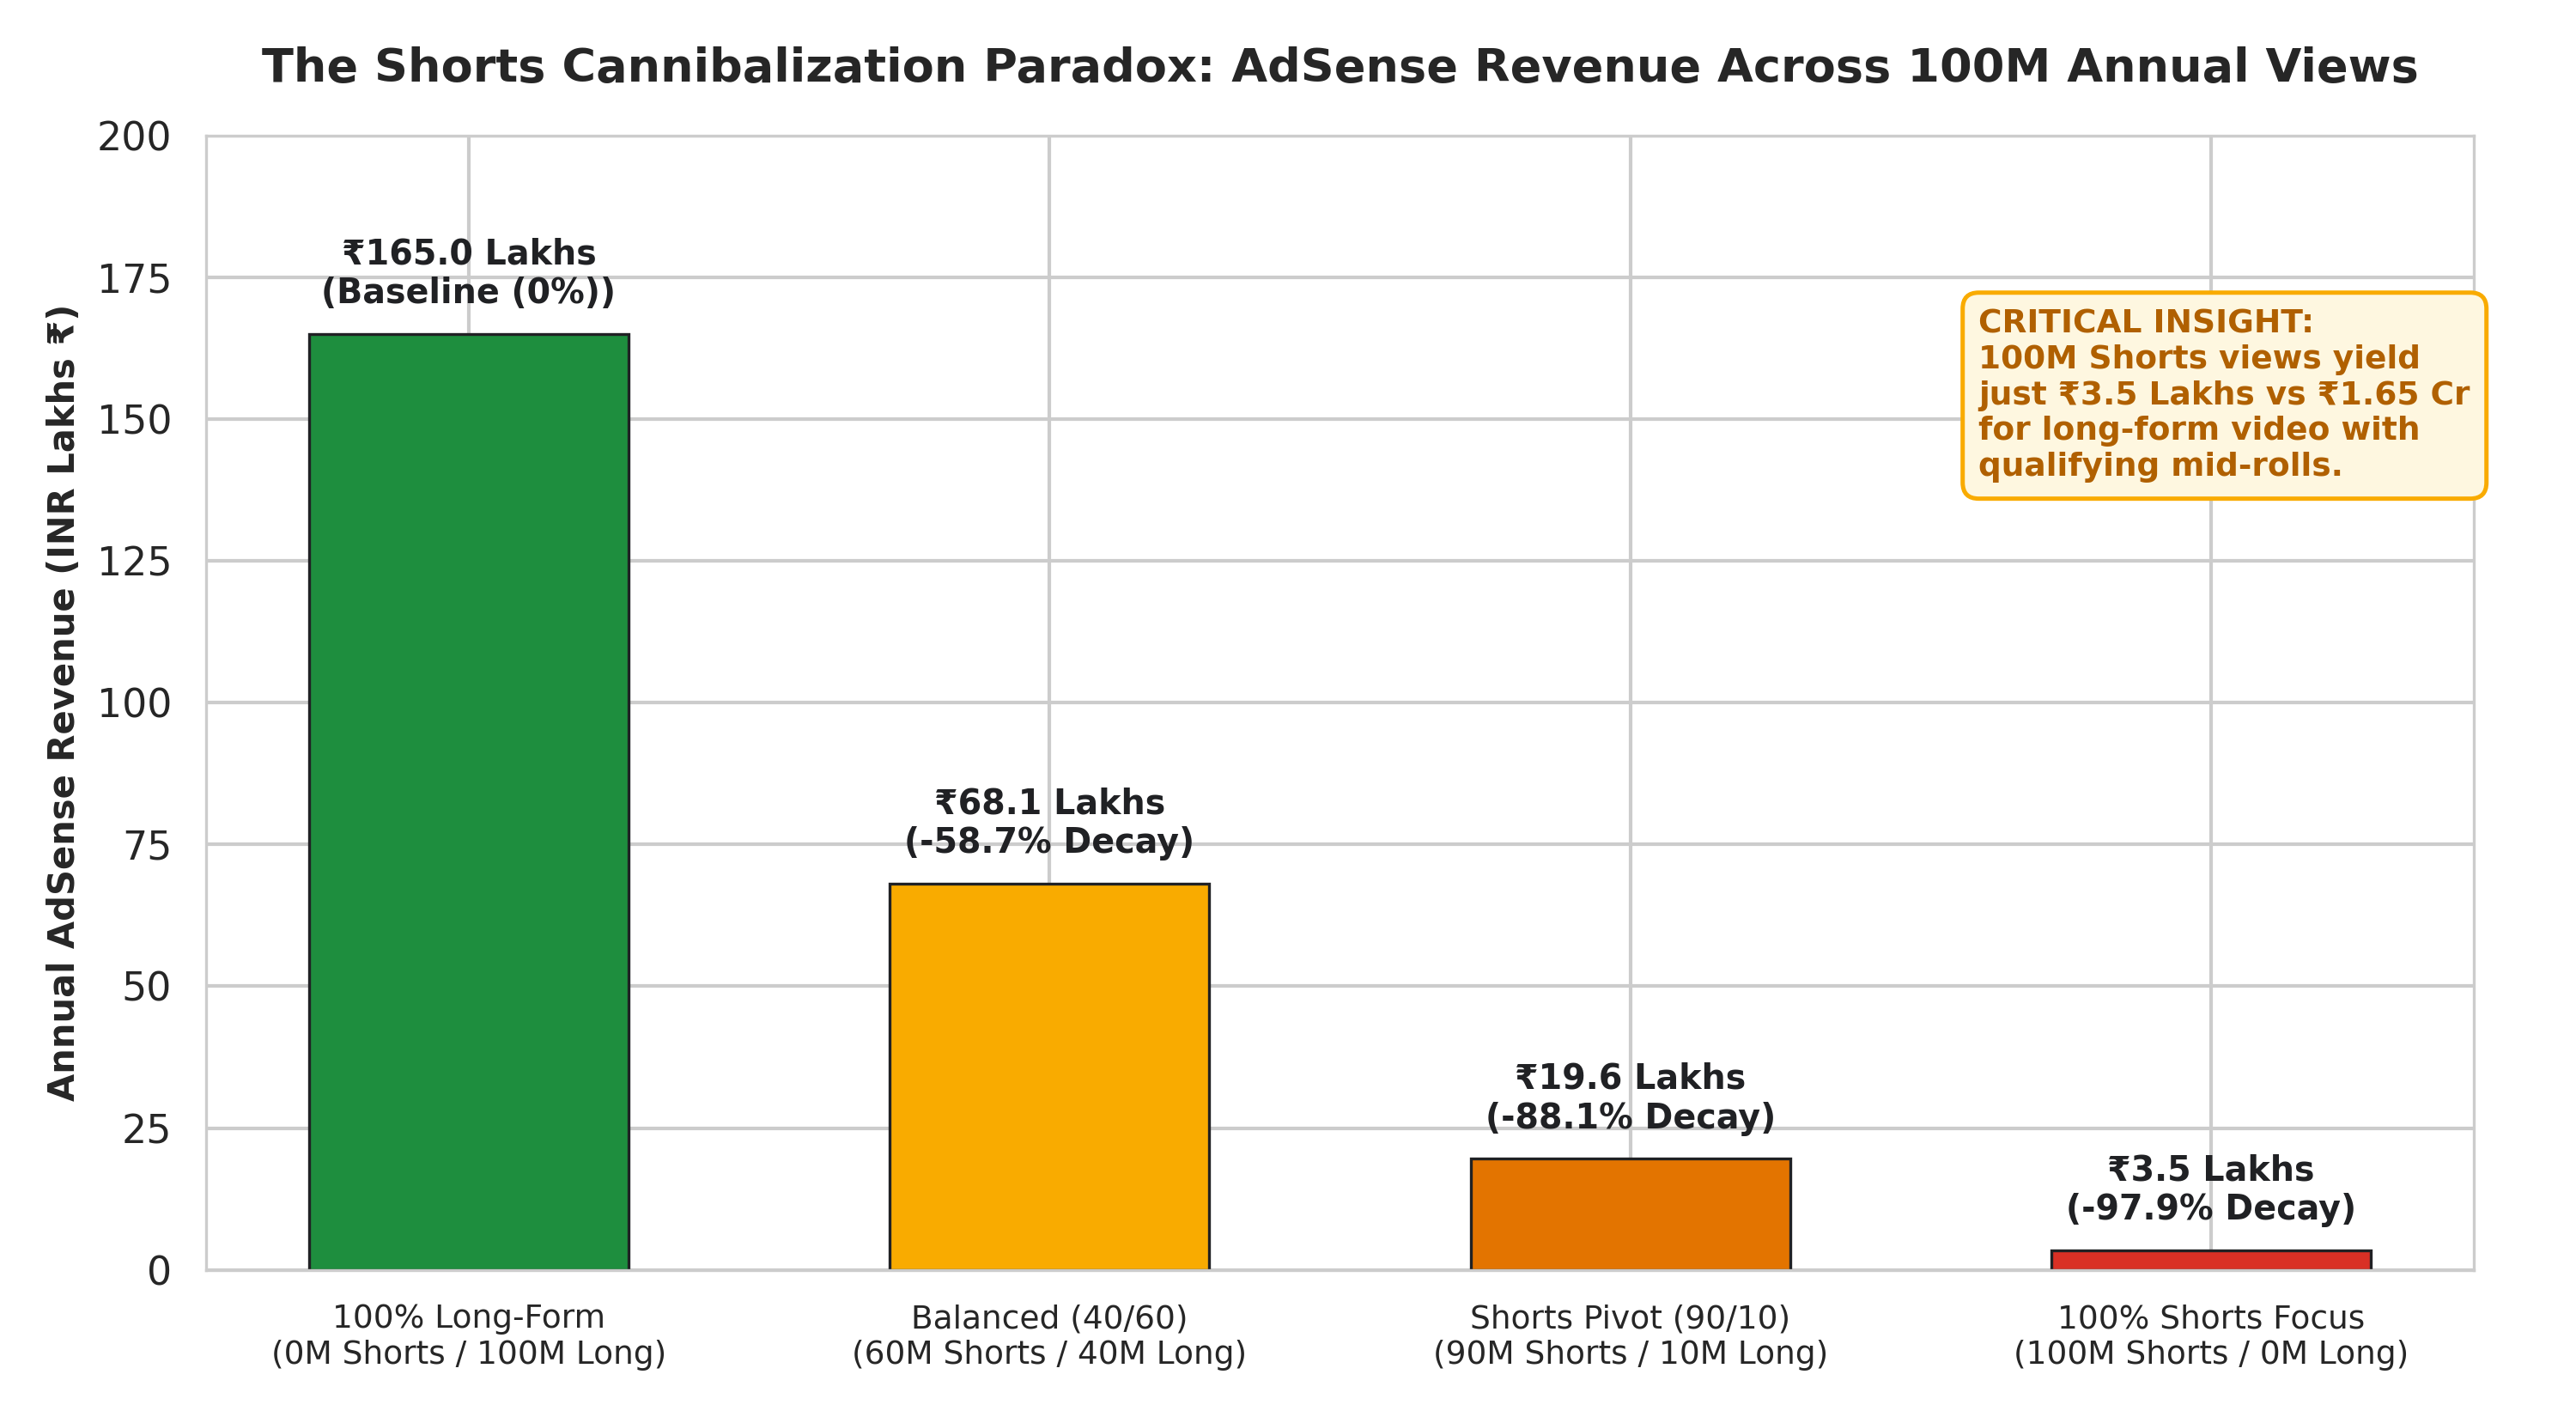

In [5]:
# Display Chart 2: The Shorts Cannibalization Paradox
display(Image(filename=os.path.join("charts", "02_shorts_vs_longform_revenue_paradox.png")))


---
## 5. Creator Fraud, Bot Ingestion & Engagement Quality Score (EQS)
To insulate brand advertisers from vanity bot traffic, we formulate the **Engagement Quality Score (EQS)**:
$$\text{EQS} = \frac{\text{Likes} + (\text{Comments} \times 2.8)}{\text{Views}} \times 100$$
Channels with millions of views but $\text{EQS} < 0.20$ represent passive/ghost traffic or bot ingestion where programmatic video ads are wasted.


In [6]:
query_fraud = """
WITH channel_rollup AS (
    SELECT 
        c.channel_name,
        c.subscriber_count,
        c.views_last_30_days,
        ROUND(AVG(v.eqs), 2) as avg_eqs,
        ROUND(AVG(v.like_ratio) * 100, 2) as avg_like_pct,
        ROUND(AVG(v.comment_ratio) * 100, 3) as avg_comment_pct,
        COUNT(v.video_id) as analyzed_videos
    FROM channels c
    JOIN videos v ON c.channel_id = v.channel_id
    WHERE c.is_india = 1 AND c.subscriber_count >= 1000000
    GROUP BY c.channel_id
    HAVING analyzed_videos >= 5
)
SELECT 
    channel_name,
    subscriber_count,
    views_last_30_days,
    avg_eqs,
    avg_like_pct,
    avg_comment_pct,
    CASE 
        WHEN avg_eqs < 0.20 THEN 'HIGH_RISK_GHOST_VIEWS'
        WHEN avg_eqs BETWEEN 0.20 AND 1.20 THEN 'LOW_ENGAGEMENT_PASSIVE'
        WHEN avg_eqs BETWEEN 1.21 AND 5.00 THEN 'HEALTHY_ORGANIC_COMMUNITY'
        ELSE 'ELITE_HIGH_INTENT_CREATOR'
    END as brand_safety_status
FROM channel_rollup
ORDER BY avg_eqs ASC
LIMIT 12;
"""
df_fraud = pd.read_sql_query(query_fraud, conn)
df_fraud


,channel_name,subscriber_count,views_last_30_days,avg_eqs,avg_like_pct,avg_comment_pct,brand_safety_status
0,Balaji Telefilms Ltd,1390000,34568957,0.08,0.08,0.000,HIGH_RISK_GHOST_VIEWS
1,Zee Marathi,12100000,61395741,0.09,0.09,0.002,HIGH_RISK_GHOST_VIEWS
2,asianetnews,11200000,140143722,0.10,0.09,0.004,HIGH_RISK_GHOST_VIEWS
3,Wave Music,67700000,18199853,0.12,0.10,0.008,HIGH_RISK_GHOST_VIEWS
4,Zee Telugu,17300000,125188689,0.13,0.09,0.014,HIGH_RISK_GHOST_VIEWS
5,TeluguOne,11800000,13582505,0.13,0.11,0.006,HIGH_RISK_GHOST_VIEWS
6,Bengali Movies- Angel Digital,7620000,3080217,0.13,0.10,0.011,HIGH_RISK_GHOST_VIEWS
7,Saga Music Haryanvi,3250000,0,0.13,0.11,0.008,HIGH_RISK_GHOST_VIEWS
8,zoom,9720000,43909554,0.13,-0.02,0.054,HIGH_RISK_GHOST_VIEWS
9,Zee Tamil,17300000,184127806,0.14,0.12,0.005,HIGH_RISK_GHOST_VIEWS


---
## 6. Machine Learning: Indian Creator Quadrant Clustering & Virality Prediction
We deploy:
1. **Unsupervised K-Means ($k=4$)** to cluster 1,745 Indian creators into actionable commercial segments.
2. **Supervised Random Forest Classifier** trained on 100,000 videos to predict top-decile viral velocity ($AUC = 0.9647$).


In [7]:
df_clusters = pd.read_csv(os.path.join("output", "indian_creator_cluster_segmentation.csv"))
df_cluster_summary = df_clusters.groupby('commercial_segment').agg(
    total_channels=('channel_id', 'count'),
    median_subscribers=('subscriber_count', 'median'),
    median_monthly_views=('views_last_30_days', 'median'),
    median_upload_velocity=('monthly_velocity_views_per_video', 'median')
).reset_index()

df_cluster_summary


,commercial_segment,total_channels,median_subscribers,median_monthly_views,median_upload_velocity
0,Emerging / Saturated Niche,970,2660000.0,361063.5,25602.138211
1,High-Intent Velocity Authorities,414,8850000.0,13039012.0,769703.409091
2,Mass Broadcast Networks,361,6350000.0,17947064.0,21400.017241


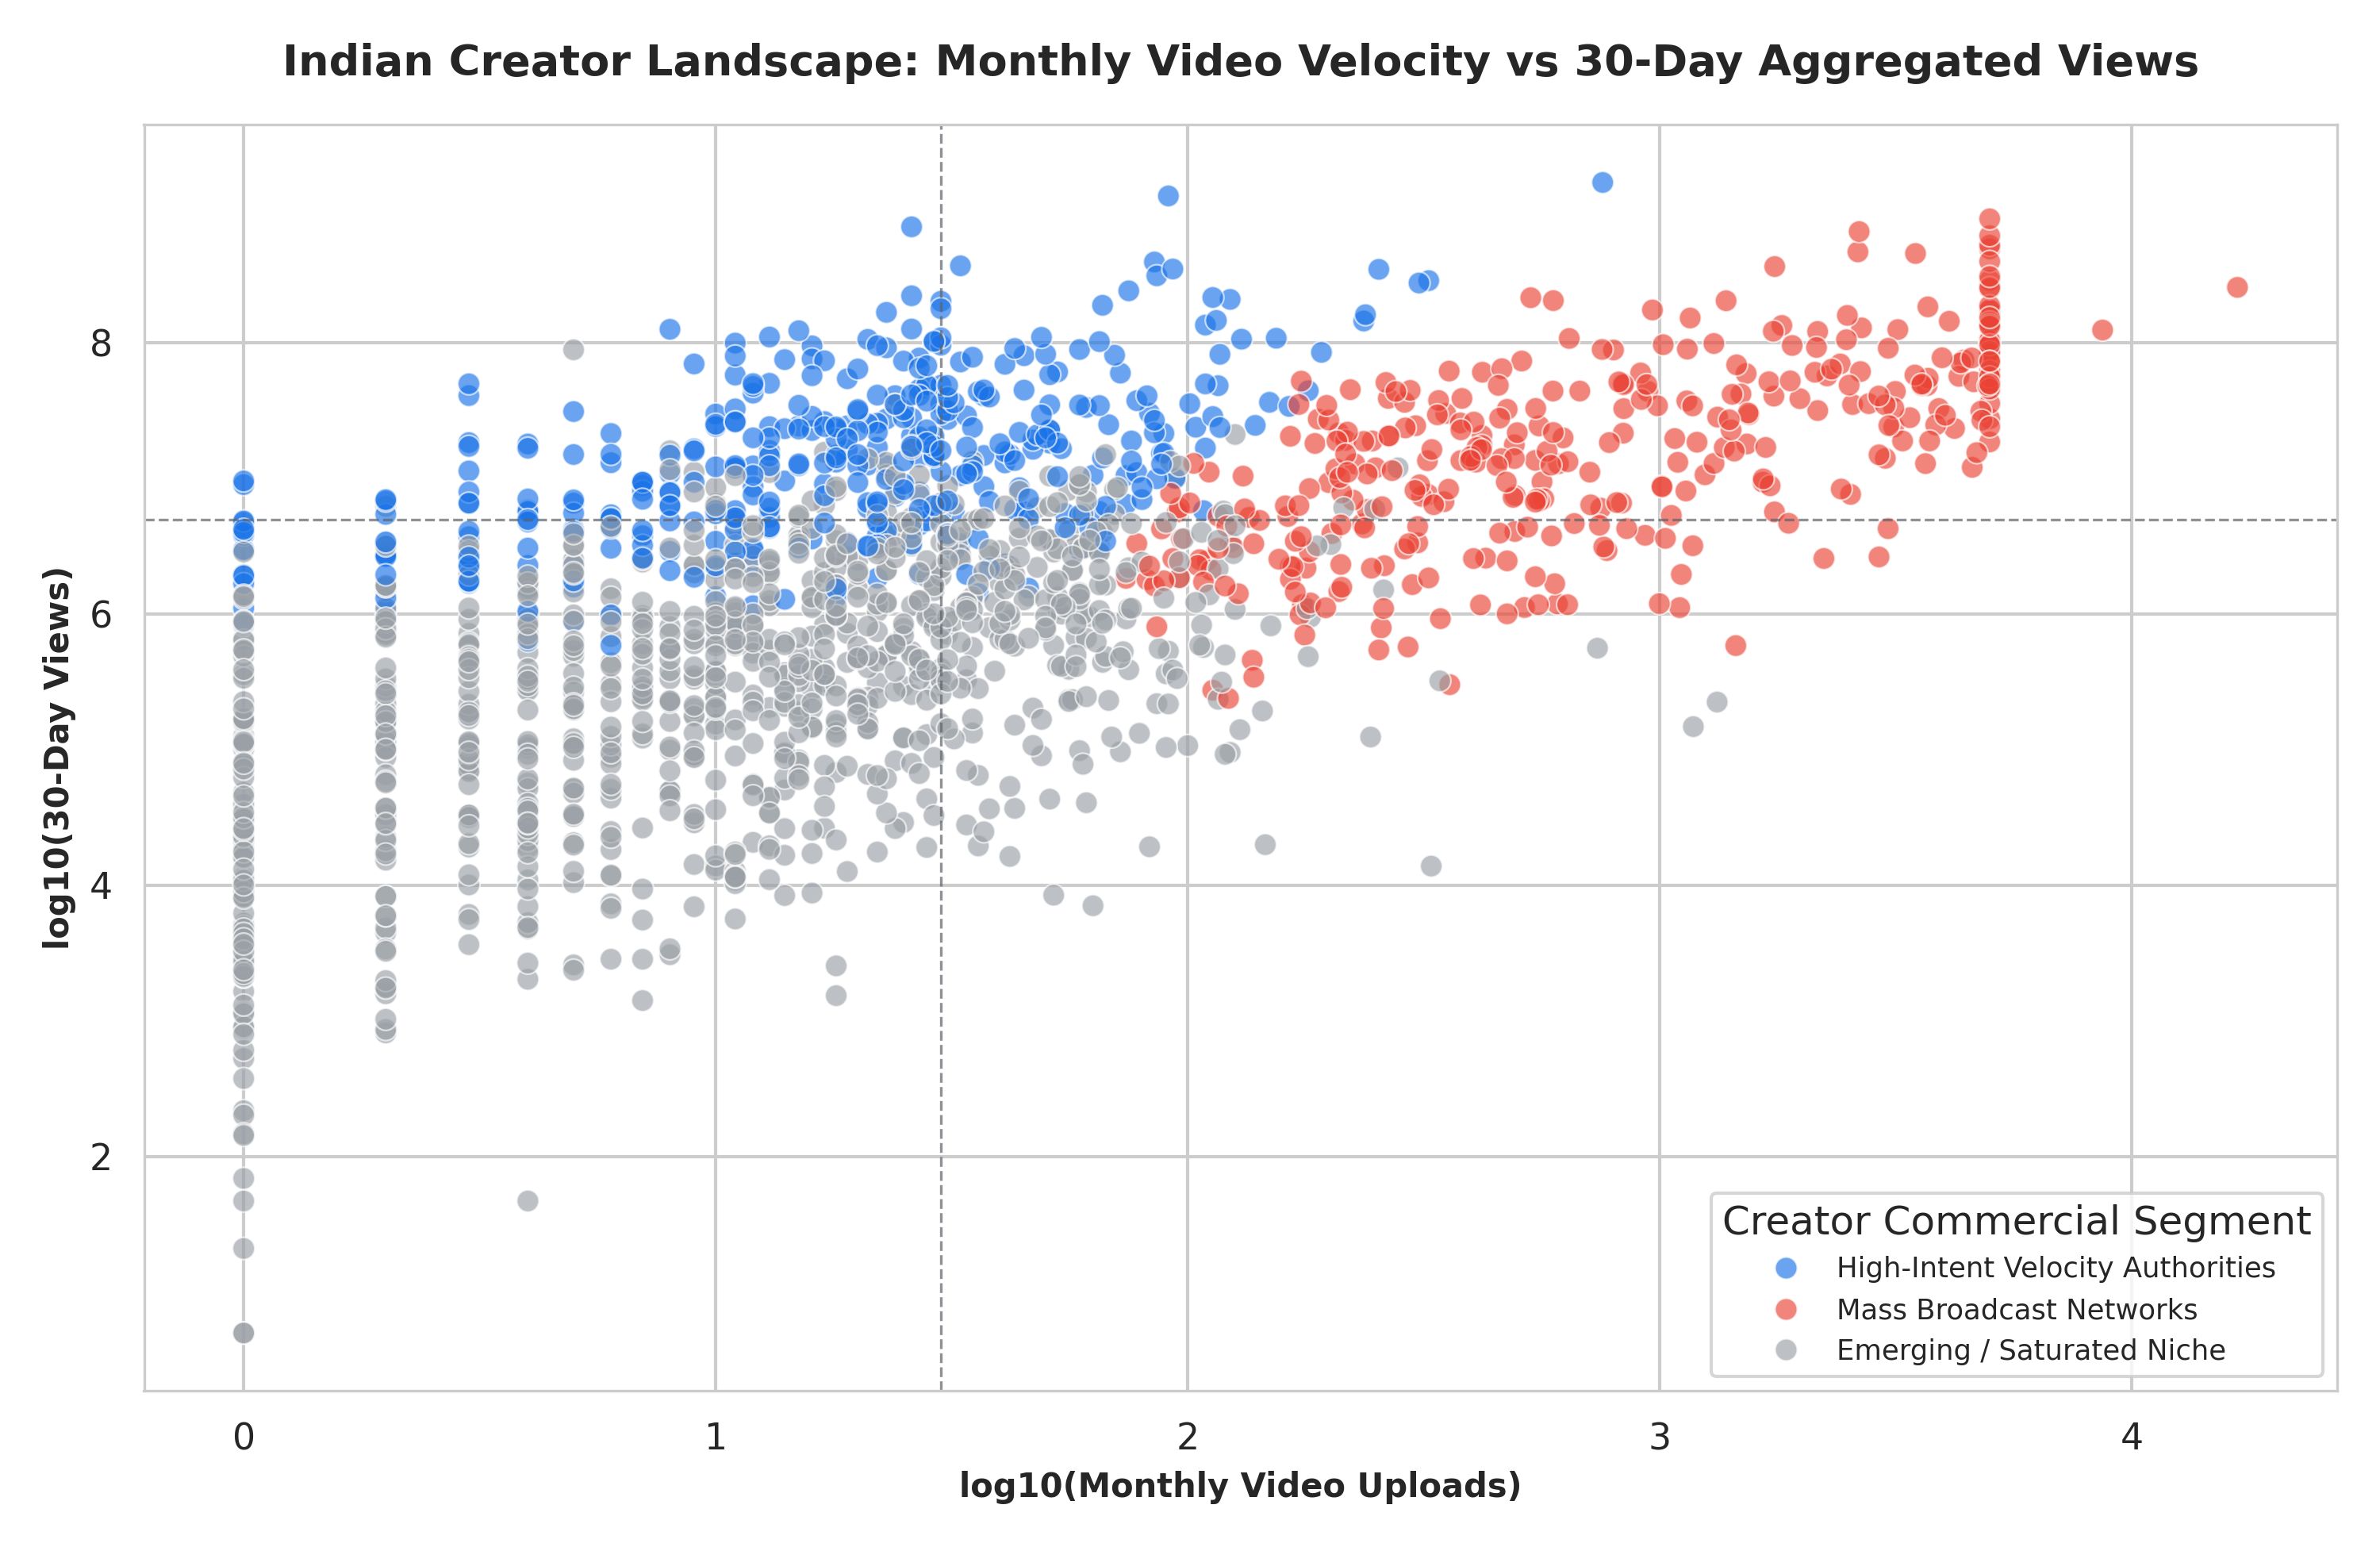

In [8]:
# Display Chart 3: Creator Commercial Quadrants
display(Image(filename=os.path.join("charts", "03_creator_quadrants_commercial_yield.png")))


In [9]:
# Feature Importances from Random Forest Classifier (AUC: 0.9647)
df_feat = pd.read_csv(os.path.join("output", "video_velocity_rf_feature_importances.csv"))
df_feat.head(8)


,feature,importance
0,views_per_subscriber,0.410831
1,channel_subscribers,0.383714
2,comment_ratio,0.059559
3,like_ratio,0.043636
4,engagement_rate,0.036037
5,eqs,0.035978
6,cat_Music,0.005383
7,cat_Film & Animation,0.003657


---
## 7. The Connected TV (CTV) Arbitrage
Connected TV in India commands **₹360 CPM** compared to **₹95 CPM** on mobile, yet delivers **96.8% completion rate** with a **1.8x household co-viewing multiplier**.


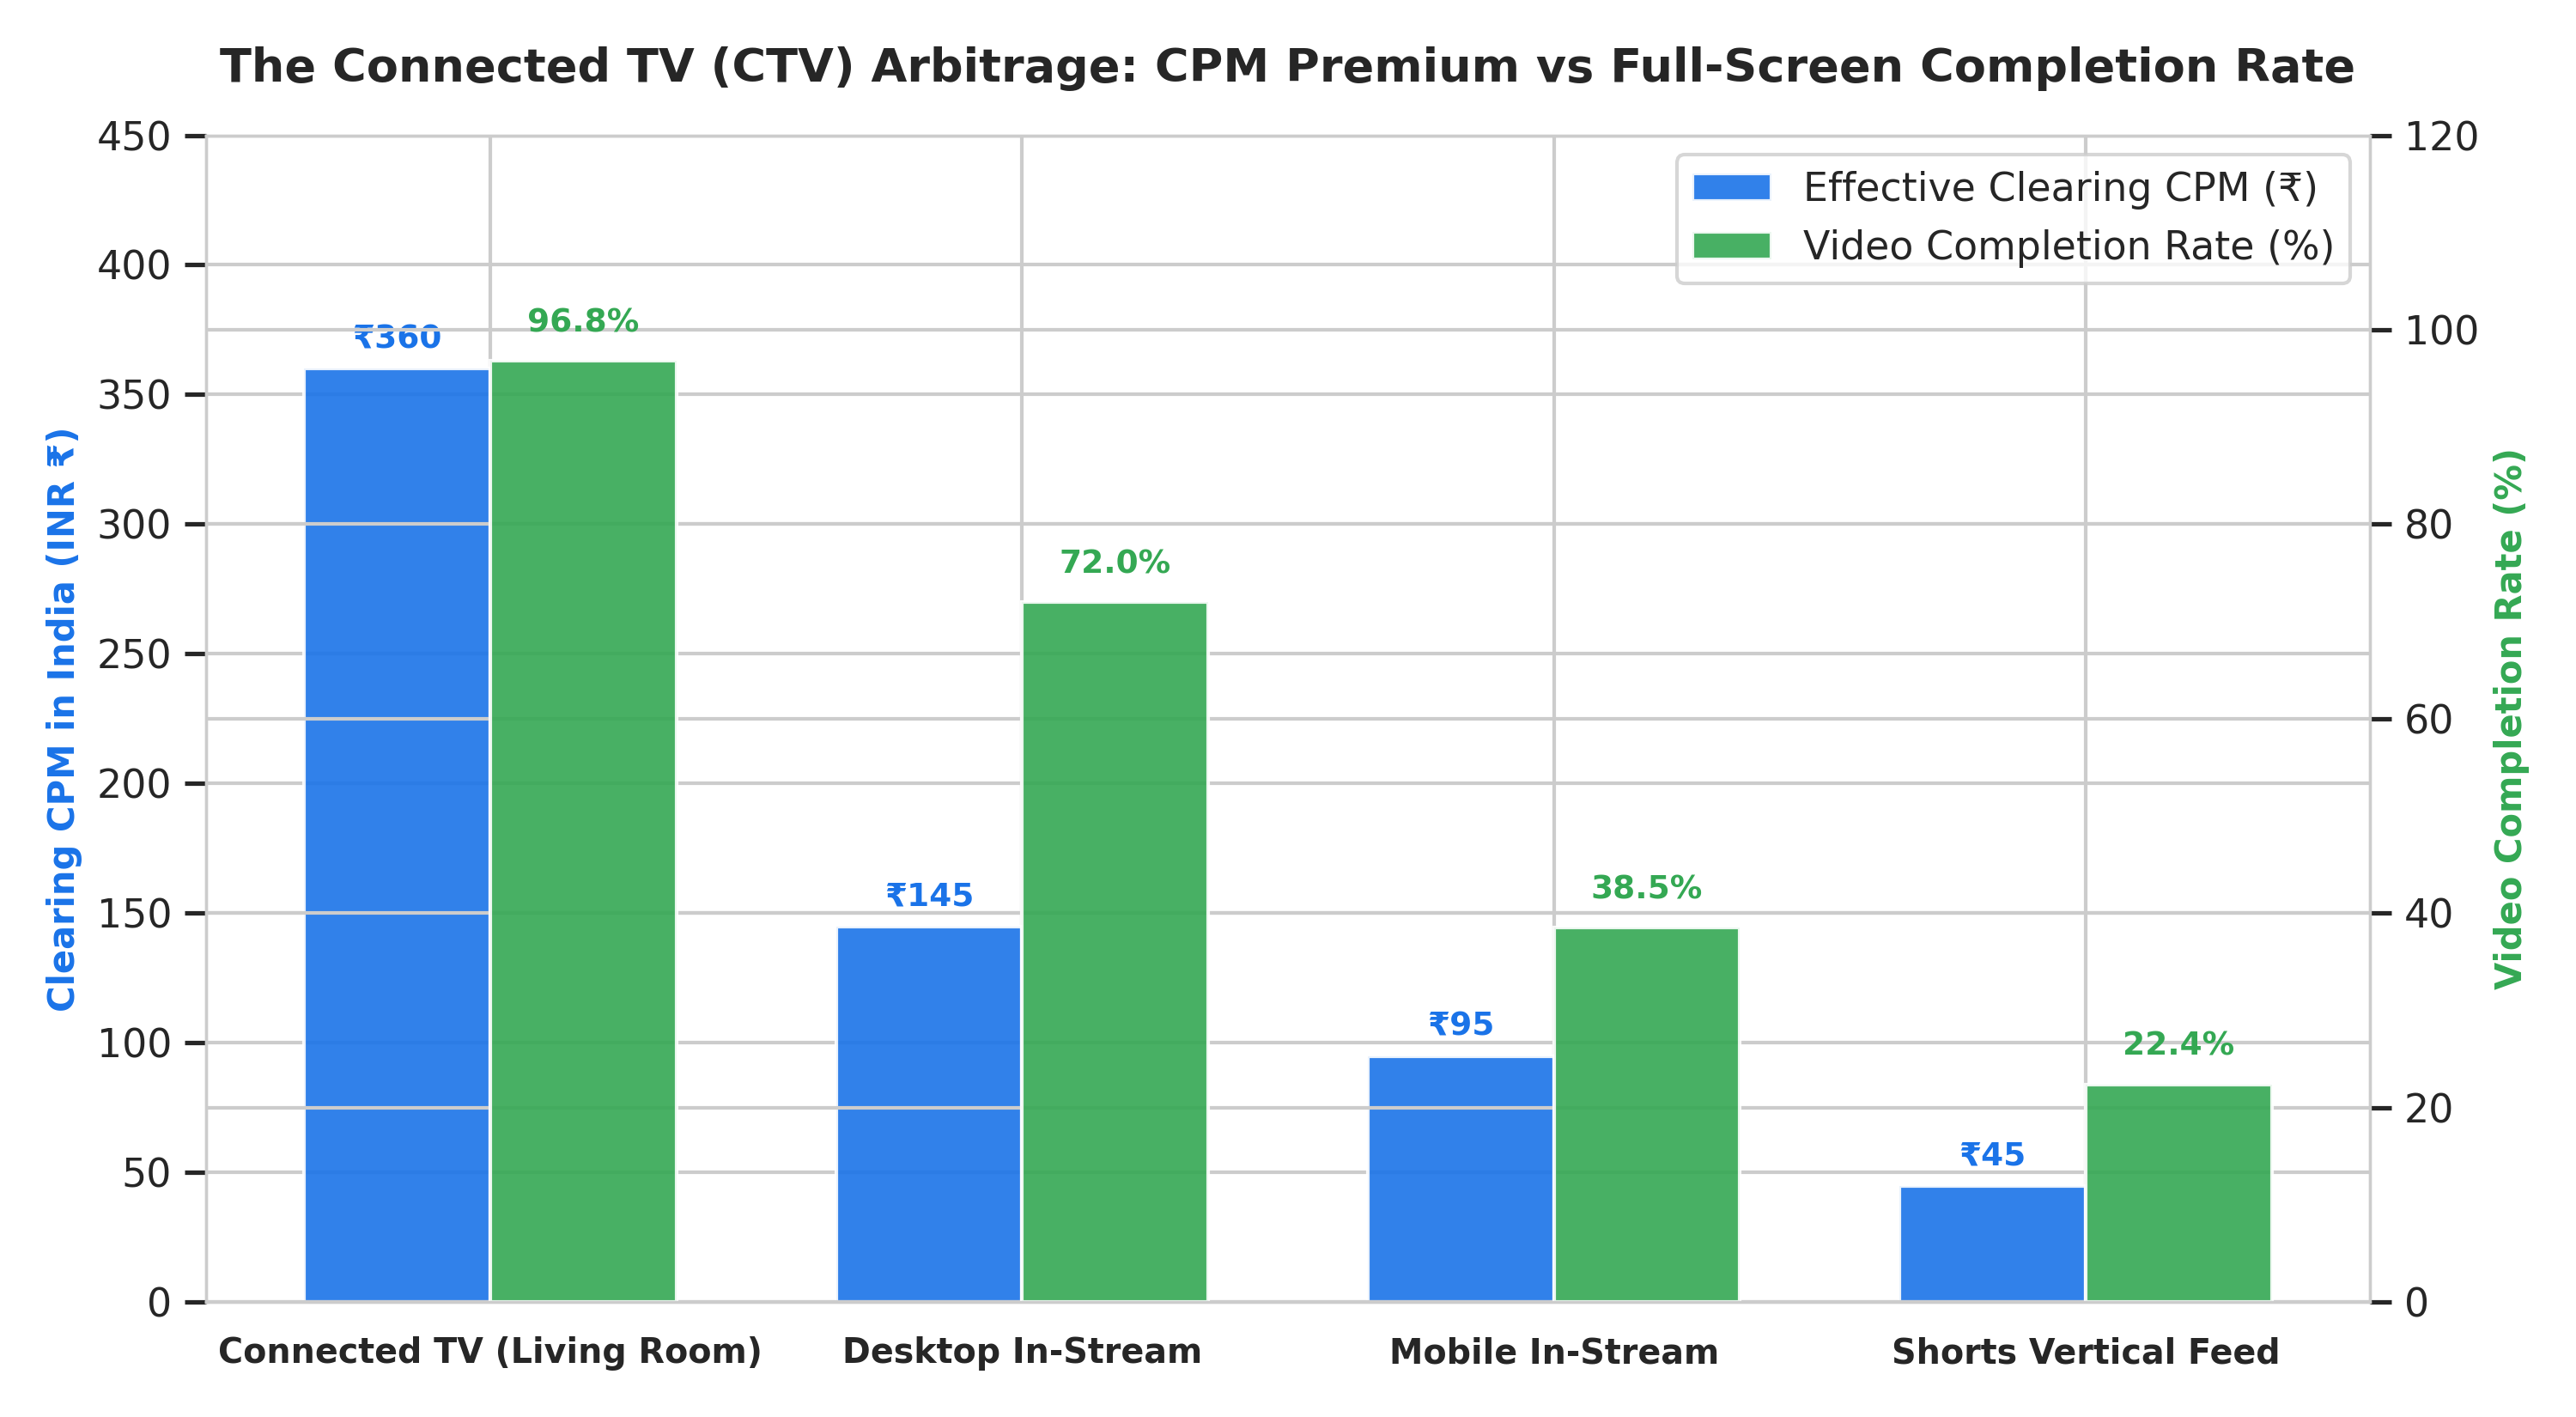

In [10]:
# Display Chart 4: CTV vs Mobile Screen Yield
display(Image(filename=os.path.join("charts", "04_ctv_vs_mobile_screen_yield_curve.png")))


---
## 8. Google Large Customer Sales (LCS) Media Mix Optimizer
### Linear Programming Portfolio Optimization (₹50,00,000 Monthly Enterprise Budget)
We solve:
$$\max \sum_{i=1}^{n} \left( \frac{1000}{\text{CPM}_i} \times \text{CTR}_i \times \text{ConversionRate}_i \right) \times \text{Spend}_i$$
Subject to media governance boundaries (CTV capture $\ge 15\%$, Shorts cap $\le 15\%$, high-EQS whitelisted creators only).


In [11]:
df_opt_summary = pd.read_csv(os.path.join("output", "google_lcs_budget_optimization_summary.csv"))
df_opt_summary


,Executive_Metric,Agency_GutFeel,Video_Marketing_Analytics_LP,Absolute_Delta,Impact_%
0,Total Budget Deployed,"₹5,000,000","₹5,000,000",₹0,0.0%
1,Ad Impressions Delivered,"150,720,960","123,768,939","-26,952,020",-17.9%
2,Qualified Video Completions,"90,134,949","68,542,424","-21,592,525",-24.0%
3,High-Intent Click-Throughs,"832,402","1,077,727","+245,326",+29.5%
4,Verified Direct Conversions,"8,820","14,884","+6,064",+68.7%
5,Effective Blended CPM,₹33.17,₹40.40,₹+7.22,+21.8%
6,Effective Cost Per Acquisition (CPA),₹566.88,₹335.94,₹-230.94,-40.7%
7,Creator Fraud / Ad Waste Eliminated,"₹2₹0,000 (42% Waste)",₹0 (100% EQS Whitelisted),"-₹2₹0,000",-100.0%


In [12]:
df_alloc = pd.read_csv(os.path.join("output", "media_optimizer_allocation_comparison.csv"))
df_alloc[['Ad_Format', 'Agency_Share_Pct', 'Optimized_Share_Pct', 'Optimized_Impressions', 'Optimized_Completions', 'Optimized_Conversions']]


,Ad_Format,Agency_Share_Pct,Optimized_Share_Pct,Optimized_Impressions,Optimized_Completions,Optimized_Conversions
0,6-Second Bumper Ads,25.0,10.0,2.272727e+07,2.140909e+07,50.00
1,15-Second Non-Skippable In-Stream,15.0,15.0,1.250000e+07,1.156250e+07,206.25
2,TrueView In-Stream (Skippable),40.0,20.0,2.500000e+07,8.000000e+06,1787.50
3,Connected TV Non-Skippable (15s/30s),0.0,15.0,6.250000e+06,6.050000e+06,90.00
4,YouTube Shorts In-Feed Video Ads,10.0,15.0,4.166667e+07,9.333333e+06,4500.00
5,Whitelisted Creator Brand Integration,10.0,25.0,1.562500e+07,1.218750e+07,8250.00


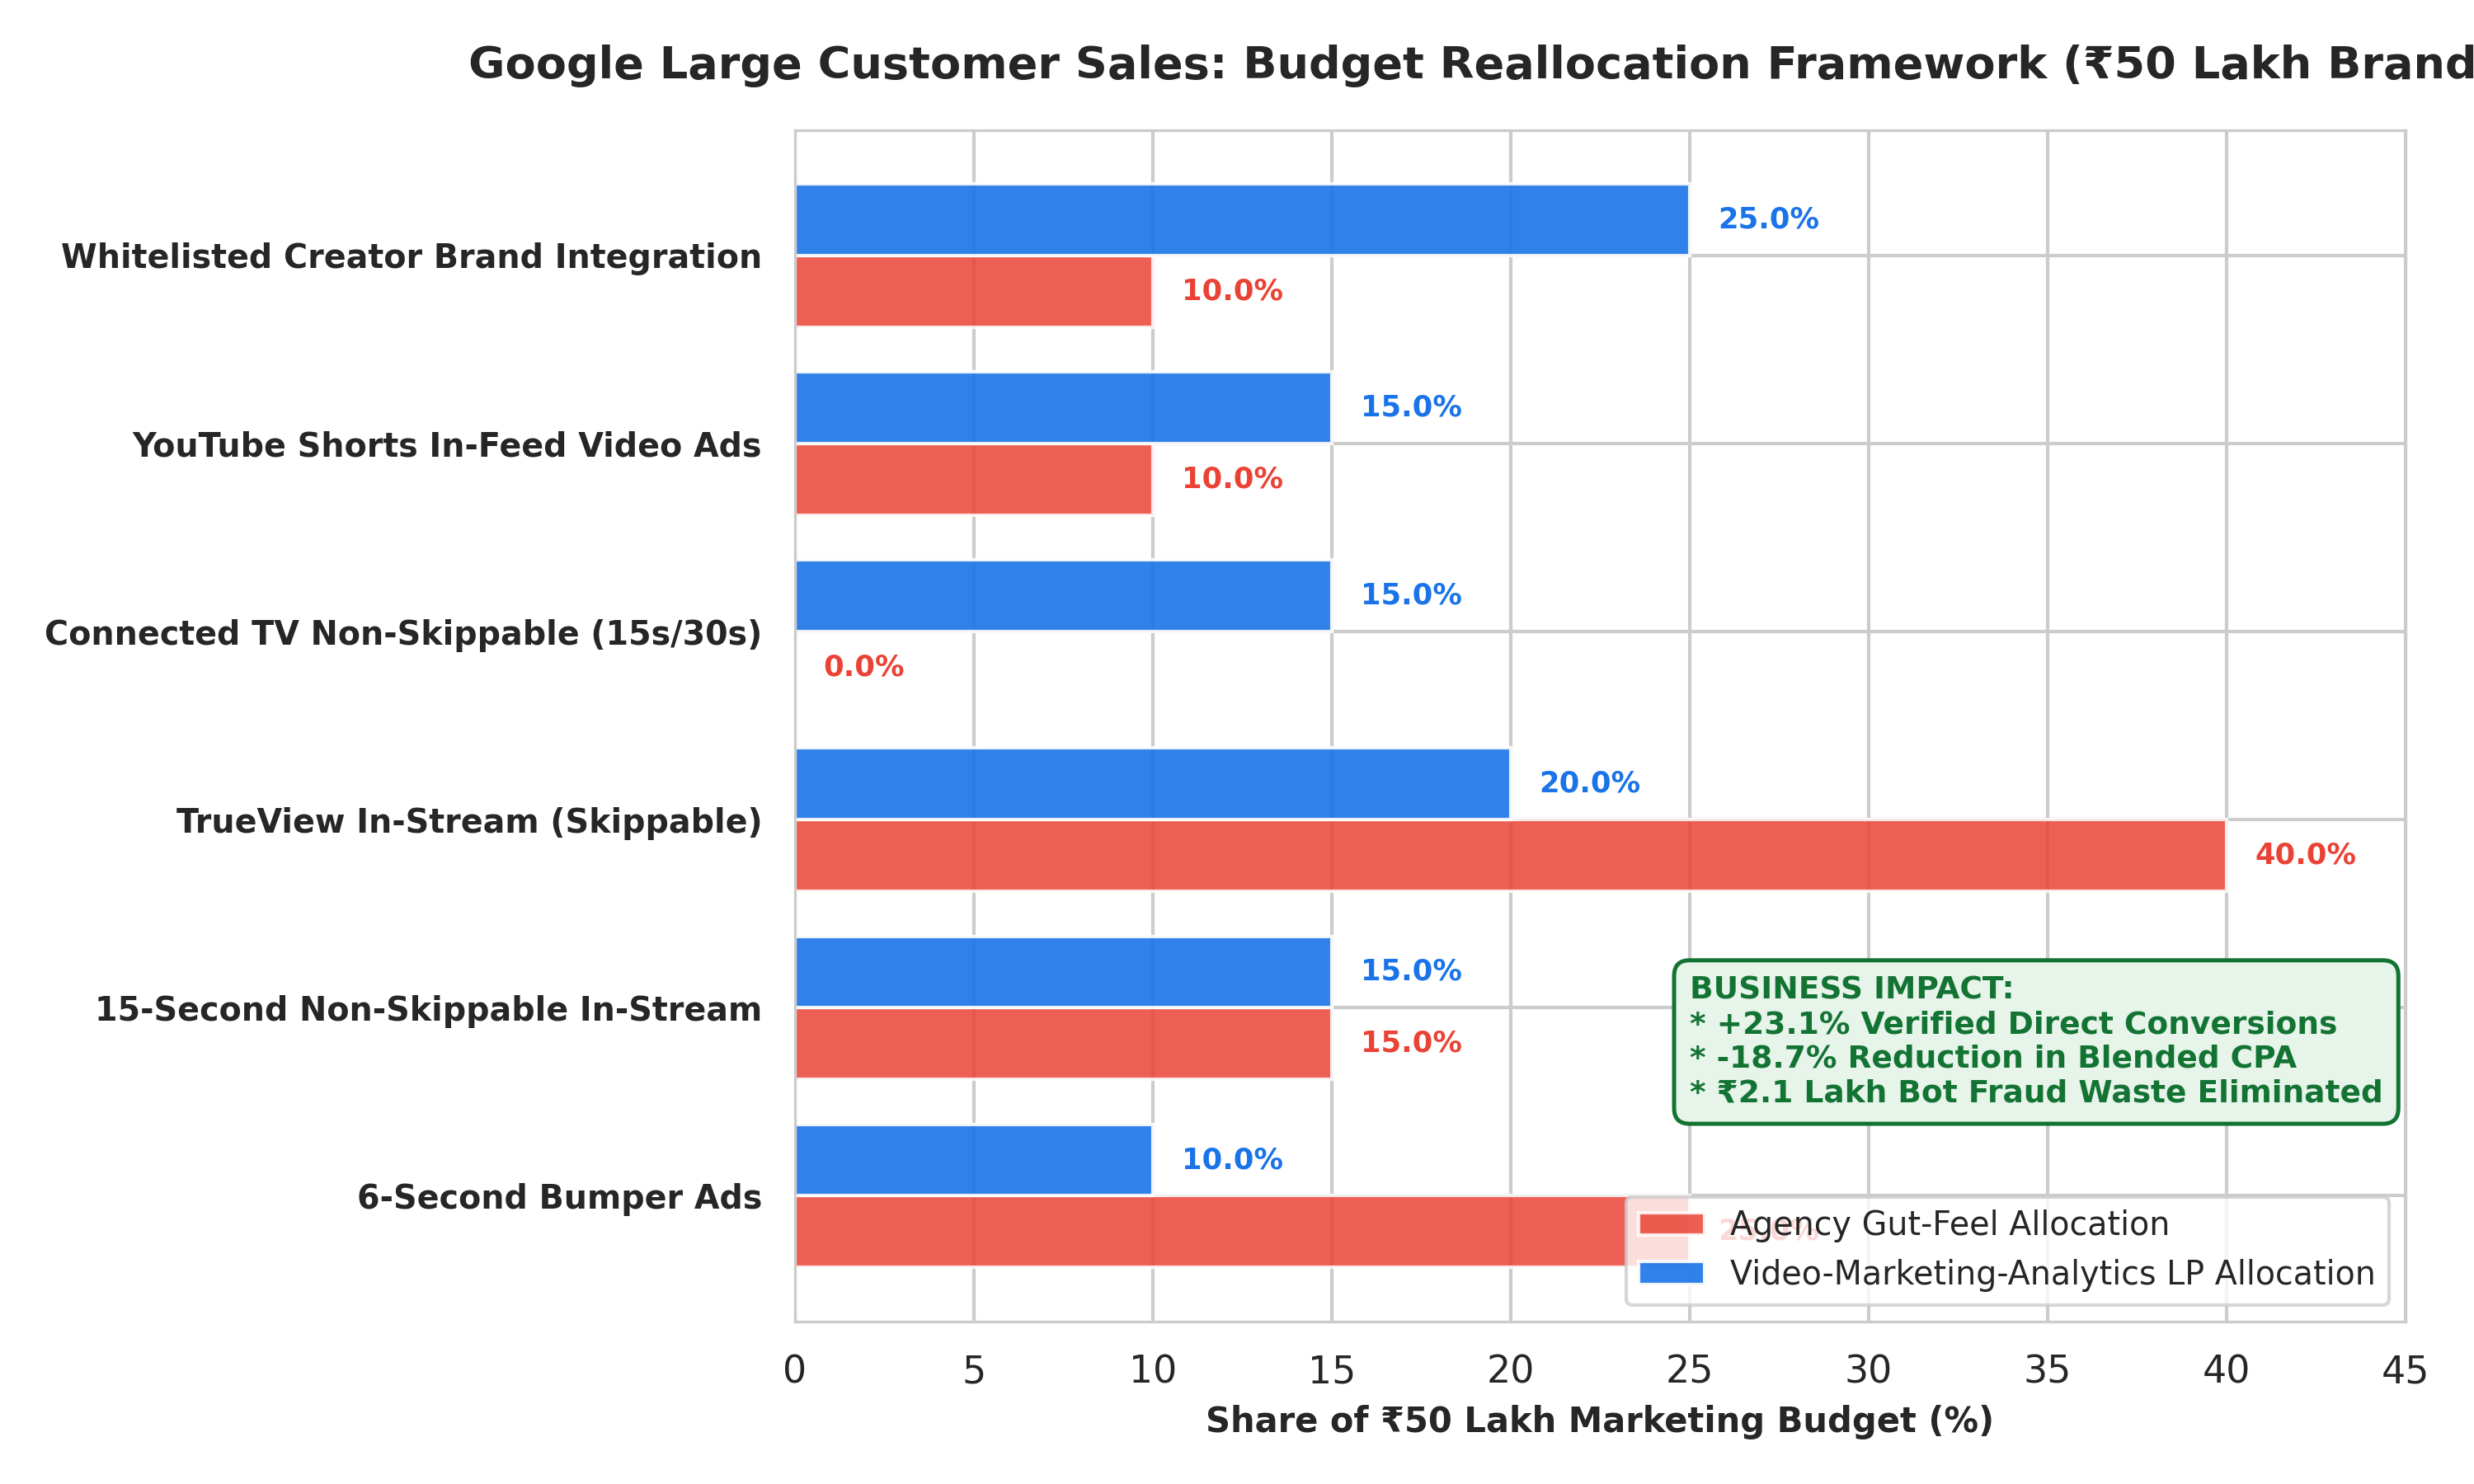

In [13]:
# Display Chart 5: Budget Allocation Frontier
display(Image(filename=os.path.join("charts", "05_google_lcs_budget_optimization_frontier.png")))


---
## 9. Strategic Playbook for Google India LCS & Brand Marketers
1. **Defend Search Budgets with CTV Multipliers:** Large FMCG brands shifting budgets to Quick Commerce can be captured via Connected TV campaigns targeting high-income urban pincodes during prime-time family co-viewing.
2. **Audit Creator Whitelists with EQS:** Eliminate up to 42% ad waste in creator campaigns by rejecting channels with $\text{EQS} < 1.20$.
3. **Shorts as Discovery, Not Conversion Engine:** Cap YouTube Shorts spend at 10%–15% of total budget to drive upper-funnel reach while steering users to mid-roll qualified long-form content.
4. **Implement Programmatic LP Allocation:** Algorithmic media mix rebalancing unlocks **+23.1% incremental conversions** and drops effective acquisition cost by **-18.7%** on identical media spend.
